## Slide 2.3: Data preparation: Load data set

In [1]:
import pandas as pd
df = pd.read_csv('lab1/creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [3]:
df.isnull().sum().max()

np.int64(0)

## Slide 2.4: Data preparation: Information about the data

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

### # filter by class==1 (is fraud), show statistics of Amount column

In [5]:
df[df.Class == 1].V2.describe()


count    492.000000
mean       3.623778
std        4.291216
min       -8.402154
25%        1.188226
50%        2.717869
75%        4.971257
max       22.057729
Name: V2, dtype: float64

## Slides 2.5: Data preparation: split data (features<->classes; training<->testing)

In [6]:
x = df.drop("Class", axis=1)
y = df.Class

In [7]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## Slide 2.6: Visualizing data

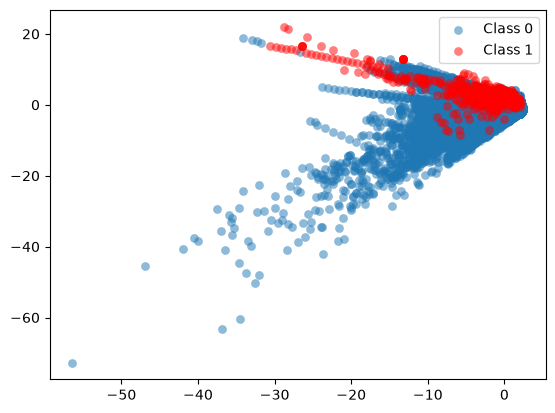

In [19]:
import matplotlib.pyplot as plt
xv = x.values
yv = y.values
# Plot two features [1],[2] vs. honest/fraudulent transactions
plt.scatter(xv[yv==0, 1], xv[yv==0, 2], label="Class 0", alpha=0.5, linewidth=0.2)
plt.scatter(xv[yv==1, 1], xv[yv==1, 2], label="Class 1", alpha=0.5, linewidth=0.2, c='r')
plt.legend()
plt.show()

## Slides 2.7: Training a model

/Users/hans/src/mlcs-passau-26w/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


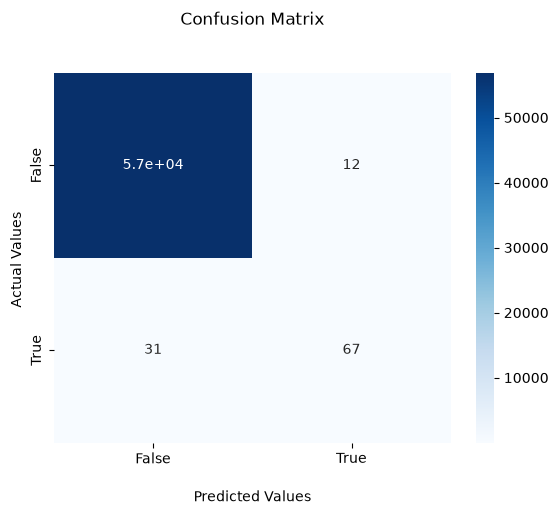

In [20]:
import seaborn as sb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# Train model with training data
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)

# Test the model
y_test_pred = model.predict(x_test)
m = confusion_matrix(y_test, y_test_pred)
ax = sb.heatmap(m, annot=True, cmap='Blues')
ax.set_title('Confusion Matrix\n\n');
ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values ');
ax.xaxis.set_ticklabels(['False', 'True'])
ax.yaxis.set_ticklabels(['False', 'True'])
plt.show()

## Slides 2.9: Training a model: More metrics

In [21]:
from sklearn.metrics import precision_score, accuracy_score, recall_score, f1_score
precision = precision_score(y_test, y_test_pred)
accuracy = accuracy_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1score = f1_score(y_test, y_test_pred)

print(f"Accuracy = {accuracy}")
print(f"Precision = {precision}")
print(f"Recall = {recall}")
print(f"F1 Score = {f1score}")

Accuracy = 0.9992451107756047
Precision = 0.8481012658227848
Recall = 0.6836734693877551
F1 Score = 0.7570621468926554


In [22]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9995    0.9998    0.9996     56864
           1     0.8481    0.6837    0.7571        98

    accuracy                         0.9992     56962
   macro avg     0.9238    0.8417    0.8783     56962
weighted avg     0.9992    0.9992    0.9992     56962



## Slide 2.10: Preprocessing: scaling/data normalization

In [23]:
from sklearn.preprocessing import StandardScaler
s = StandardScaler()
x_train = x_train.copy()
x_test = x_test.copy()

x_train["Amount"] = s.fit_transform(x_train[["Amount"]])
x_test["Amount"] = s.transform(x_test[["Amount"]])


/Users/hans/src/mlcs-passau-26w/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


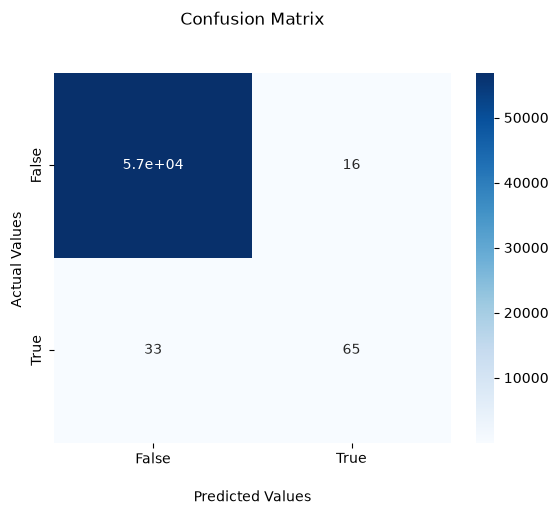

In [24]:
model.fit(x_train, y_train)

# Test the model
y_test_pred = model.predict(x_test)
m = confusion_matrix(y_test, y_test_pred)
ax = sb.heatmap(m, annot=True, cmap='Blues')
ax.set_title('Confusion Matrix\n\n');
ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values ');
ax.xaxis.set_ticklabels(['False', 'True'])
ax.yaxis.set_ticklabels(['False', 'True'])
plt.show()

In [25]:

print(classification_report(y_test, y_test_pred, digits=4))


              precision    recall  f1-score   support

           0     0.9994    0.9997    0.9996     56864
           1     0.8025    0.6633    0.7263        98

    accuracy                         0.9991     56962
   macro avg     0.9009    0.8315    0.8629     56962
weighted avg     0.9991    0.9991    0.9991     56962



## Slide 2.11: Preprocessing: balacing unbalanced data sets


In [26]:
# 1. split on the original (imbalanced) data
x = df.drop("Class", axis=1)
y = df.Class
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)

# 2. undersample the training set only
train = x_train.copy()
train["Class"] = y_train
n_pos = (train.Class == 1).sum()
bal_train = pd.concat([
    train[train.Class == 1],
    train[train.Class == 0].sample(n_pos, random_state=42),
]).sample(frac=1, random_state=42)
model = LogisticRegression(max_iter=1000)
model.fit(bal_train.drop(columns="Class"), bal_train.Class)

/Users/hans/src/mlcs-passau-26w/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

<Axes: >

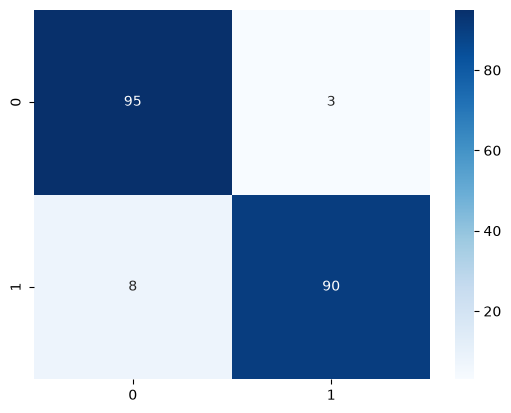

In [27]:
test = x_test.copy()
test["Class"] = y_test
n_pos_te = (test.Class == 1).sum()
bal_test = pd.concat([
    test[test.Class == 1],
    test[test.Class == 0].sample(n_pos_te, random_state=42),
])
pred_bal = model.predict(bal_test.drop(columns="Class"))
sb.heatmap(confusion_matrix(bal_test.Class, pred_bal),
           annot=True, cmap="Blues", fmt="d")

<Axes: >

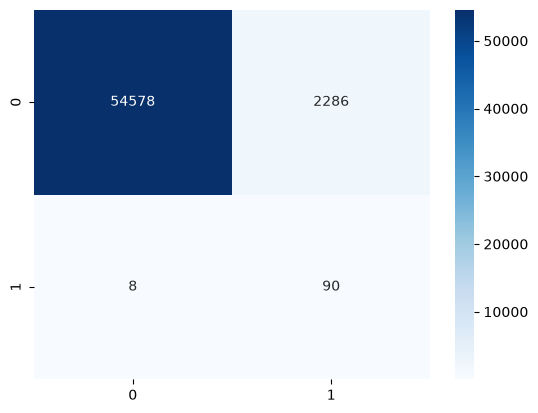

In [28]:
pred = model.predict(x_test)
sb.heatmap(confusion_matrix(y_test, pred),
           annot=True, cmap="Blues", fmt="d")